# Q5 — completed small U-Net pipeline

**Names / NetIDs:** [fill before submission]

Train separate two-level U-Nets from scratch for in-vivo and ex-vivo cells, then use automatic triangle registration, guarded affine ICP and one-to-one matching. The user authorized this neural extension; the classical notebook and older experiment artifacts remain available.

The competition measures **S = 0.25 PQ_invivo + 0.25 PQ_exvivo + 0.50 F1_match**, not pixel accuracy. A mask must have IoU **strictly greater than 0.75**. The 0.70 target is not a measured result.

Sources: L5 p.111 and L6 pp.61–66,70 for modality-specific normalization, patches, augmentation, Dice and validation; L5 codelab cells18–20 for RLE/CSV and25–27 for diagnostics. The small U-Net architecture and foreground/core targets are new adaptations. Geometry reuses our Q1–Q3 robust-fitting concepts and Q5 classical helper; inference never uses annotated correspondence pairs. Checkpoints use [PyTorch state dictionaries](https://docs.pytorch.org/docs/stable/notes/serialization.html); discrete masks use [scikit-image watershed](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.watershed).

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, tifffile, torch
from skimage.segmentation import mark_boundaries
from cell_matching import read_pair, decode_rle, normalize, summarize, validate_submission
from unet_cells import (SmallUNet, device, grouped_validation, train_models, load_models,
                        predict_pair, write_submission, EPOCHS, STEPS, BATCH, PATCH)

root, out = Path('Data'), Path('outputs/q5/unet_complete')
rows = pd.read_csv(root / 'training/train_ground_truth.csv')
# Training was executed and saved. Set True to repeat all three folds and final fitting.
RETRAIN = False
print(torch.__version__, device, len(rows), 'training regions')
print('Parameters per modality:', sum(p.numel() for p in SmallUNet().parameters()))
print(f'{EPOCHS} epochs × {STEPS} steps × {BATCH} patches; patch size {PATCH}')

2.14.1 mps 47 training regions
Parameters per modality: 118642
36 epochs × 60 steps × 8 patches; patch size 128


## 1. Training and preprocessing

`unet_cells.py` contains the original small network, patch sampling and tiled inference so runnable submission code shares the notebook implementation. Original TIFFs remain uint16; percentile normalization creates processing arrays. Paired rotations/flips, intensity gain/gamma and light noise augment patches. Sampling balances cell centers, bright unannotated background and uniform locations.

Two output channels predict foreground and eroded instance cores. Train with boundary-weighted BCE plus Dice for a fixed 36-epoch budget; no checkpoint selection using excluded labels. Foreground thresholds {0.4,0.5,0.6} and core seed strategies (local peaks or components) are calibrated on weight-training regions only. Native-resolution overlapping tiles and seeded watershed produce separate instances; area limits come from training mask quantiles.

In [2]:
if RETRAIN:
    evaluation, summary = grouped_validation(rows, out, root)
else:
    evaluation = pd.read_csv(out / 'evaluation_per_region.csv')
    summary = summarize(evaluation)
assert set(evaluation.sample_id) == set(rows.sample_id) and evaluation.sample_id.is_unique
for mouse in evaluation.excluded_mouse.unique():
    metadata = json.loads((out / mouse / 'experiment.json').read_text())
    excluded = set(evaluation.loc[evaluation.excluded_mouse == mouse, 'sample_id'])
    assert set(metadata['training_ids']).isdisjoint(excluded)
    assert {i.split('__')[0] for i in metadata['training_ids']} == set(rows.sample_id.str.split('__').str[0]) - {mouse}
folds = pd.DataFrame({mouse: summarize(group) for mouse, group in evaluation.groupby('excluded_mouse')}).T
display(folds.round(4))
classical = json.loads(Path('outputs/q5/refinement/grouped_summary.json').read_text())
classical = {key: classical[key] for key in summary}
display(pd.DataFrame({'Classical refined': classical, 'Small U-Net': summary}).T.round(4))
ceiling = .25*(summary['pq_invivo']+summary['pq_exvivo']) + .5*(2*evaluation.recoverable_pairs.sum()/(evaluation.recoverable_pairs.sum()+evaluation.verified_pairs.sum()))
print('Correct / predicted / verified pairs:', evaluation[['correct_pairs','predicted_pairs','verified_pairs']].sum().to_dict())
print('Oracle matching ceiling with these fixed masks:', round(ceiling,4))

,pq_invivo,pq_exvivo,f1_match,score
subject_5d294c,0.4841,0.3309,0.2545,0.3310
subject_b2ba5e,0.5489,0.3096,0.1471,0.2882
subject_db6b8b,0.6360,0.3896,0.3452,0.4290


,pq_invivo,pq_exvivo,f1_match,score
Classical refined,0.4535,0.2434,0.0957,0.2221
Small U-Net,0.5602,0.3475,0.2840,0.3689


Correct / predicted / verified pairs: {'correct_pairs': 277, 'predicted_pairs': 812, 'verified_pairs': 1139}
Oracle matching ceiling with these fixed masks: 0.537


## 2. Validation interpretation

Every region is scored by models trained on the other two mice. Modality PQs average across regions; matching F1 pools pair counts. All three mice were examined in earlier work, and matching settings were developed there: this is **retrospective grouped development validation**, not an untouched independent estimate. Training-only threshold calibration is also in-sample; three mice give limited evidence of generalization. Empty cases follow our reconstructed scorer, since the official scorer remains unavailable.

Triangle geometry uses predicted cell locations. Support is a geometric score, not a probability; ambiguous alignment may produce no pairs. Unverified cells are not confirmed correspondence negatives. The oracle figure assumes perfect selection of recoverable verified pairs and cannot be attained merely by changing an assignment threshold.

**Measured result:** grouped S = **0.3689**, versus **0.2221** for the refined classical pipeline. PQ_invivo = 0.5602, PQ_exvivo = 0.3475 and pooled matching F1 = 0.2840 (277 correct / 812 predicted / 1,139 verified pairs). The original U-Net experiment scored 0.2537 on the same 18-region mouse where the completed pipeline scores 0.4290; this includes both neural and geometry/postprocessing improvements.

The 0.70 target is not achieved. An oracle selecting every recoverable verified pair with these fixed masks reaches only **0.5370**. Ex-vivo mask quality remains weak, and registration abstains on 29 of 47 excluded regions. The first displayed region is a failure case: support 0.094 is below 0.16, giving no pairs despite six recoverable correspondences. Its ex-vivo prediction also includes masks absent from the released annotations. Hidden-test predictions have no measured accuracy; 23 of 29 regions receive no pairs.

,threshold,seeds
invivo,0.5,components
exvivo,0.6,components


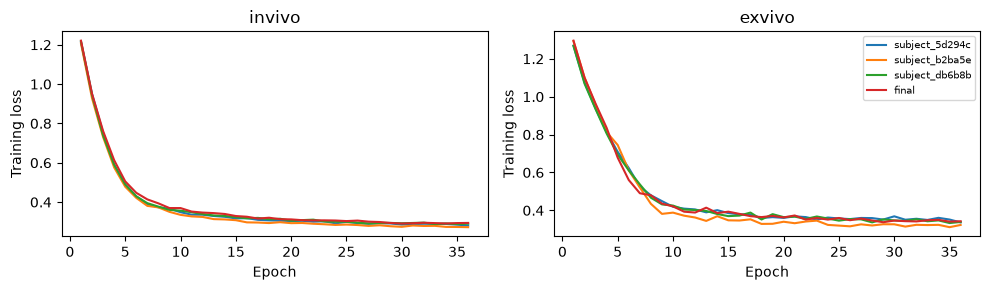

In [3]:
if RETRAIN:
    train_models(rows, out / 'final', root)
models, metadata = load_models(out / 'final')
assert metadata['training_ids'] == rows.sample_id.tolist()
display(pd.DataFrame(metadata['postprocessing']).T)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for modality, ax in zip(['invivo','exvivo'], axes):
    for directory in [out / mouse for mouse in evaluation.excluded_mouse.unique()] + [out / 'final']:
        history = pd.read_csv(directory / 'training_history.csv')
        group = history[history.modality == modality]
        ax.plot(group.epoch, group.loss, label=directory.name)
    ax.set(title=modality, xlabel='Epoch', ylabel='Training loss')
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. Inspect an excluded region

Use the first dataset region, with its excluded-mouse model. Ground truth controls display crops only; it never controls segmentation, registration or matching. The full-region overlay uses the predicted affine transform.

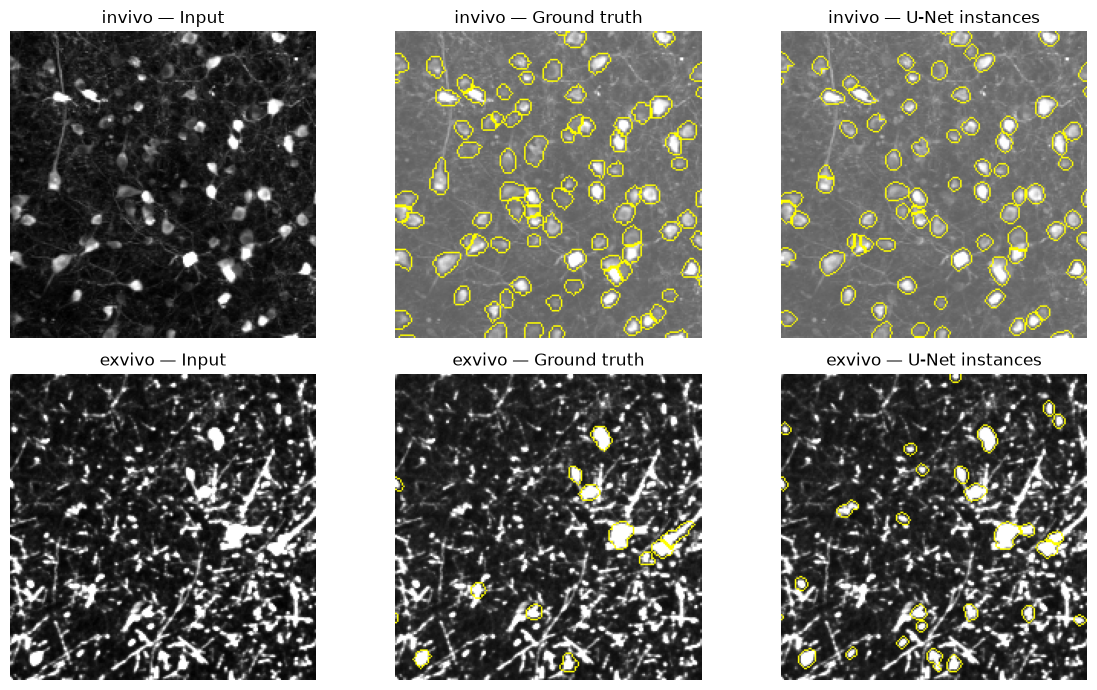

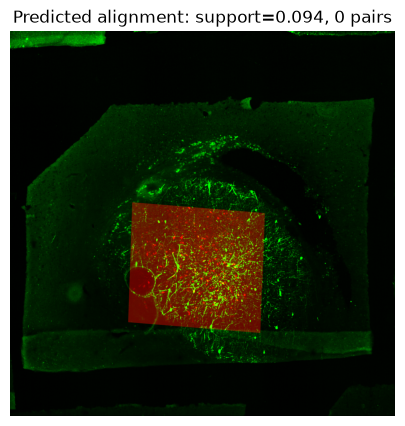

In [4]:
example = rows.iloc[0]
mouse = example.sample_id.split('__')[0]
fold_models, fold_metadata = load_models(out / mouse)
images = read_pair(root / 'training', example.sample_id)
labels, pairs, matrix, support = predict_pair(images, fold_models, fold_metadata)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for image, mask, modality, panels in zip(images, labels, ['invivo','exvivo'], axes):
    truth = np.zeros(image.shape, np.int32)
    for i, rle in enumerate(json.loads(example[modality+'_instances']).values(), 1):
        truth[decode_rle(rle, image.shape)] = i
    y, x = np.argwhere(truth > 0).mean(axis=0).astype(int)
    y, x = max(0,min(y-100,image.shape[0]-200)), max(0,min(x-100,image.shape[1]-200))
    crop = np.s_[y:y+200, x:x+200]
    for panel, view, title in zip(panels, [normalize(image)[crop],
            mark_boundaries(normalize(image)[crop], truth[crop]),
            mark_boundaries(normalize(image)[crop], mask[crop])], ['Input','Ground truth','U-Net instances']):
        panel.imshow(view, cmap='gray'); panel.set_title(modality+' — '+title); panel.axis('off')
    tifffile.imwrite(out / f'example_{modality}_labels.tif', mask)
plt.tight_layout(); plt.savefig(out / 'predictions.png', dpi=150); plt.show()
if matrix is not None:
    warped = cv2.warpAffine(normalize(images[0]), matrix, (images[1].shape[1], images[1].shape[0]))
    overlay = np.stack([warped, normalize(images[1]), np.zeros_like(warped)], -1)
    plt.figure(figsize=(8,5)); plt.imshow(overlay); plt.title(f'Predicted alignment: support={support:.3f}, {len(pairs)} pairs'); plt.axis('off')
    plt.savefig(out / 'alignment.png', dpi=150); plt.show()
del fold_models

## 4. Candidate CSV and reproduction

Final models use all 47 released training regions. Apply their saved thresholds and fixed geometry settings to the supplied sample IDs. Validate native-size RLE, IDs, schema, one-to-one pairs and CSV round trips. This creates a local candidate; no upload or final submission selection is performed.

From the project root, reproduce using saved weights:
```bash
.venv/bin/python unet_cells.py --output "Kaggle Submissions/unet_submission.csv"
```
Install core `requirements.txt` and optional `requirements-unet.txt` first in a new environment. Only released data, `cell_matching.py`, `unet_cells.py` and `outputs/q5/unet_complete/final/` are needed for inference. GPU training may vary slightly across devices; saved-weight inference was separately checked on the training device.

In [5]:
submission = write_submission(out / 'final', root)
counts = pd.DataFrame({'invivo': submission.invivo_instances.map(lambda s: len(json.loads(s))),
                       'exvivo': submission.exvivo_instances.map(lambda s: len(json.loads(s))),
                       'pairs': submission.match_pairs.map(lambda s: len(json.loads(s)))})
print('Rows:', len(submission), 'total counts:', counts.sum().to_dict())
print('Regions with no predicted pairs:', int((counts.pairs == 0).sum()))
print('CSV SHA-256:', hashlib.sha256(Path('Kaggle Submissions/unet_submission.csv').read_bytes()).hexdigest())
display(submission[['sample_id']].join(counts).head())

subject_78b6a7__region_33daed [382, 180] 0 support=0.129


subject_78b6a7__region_64dd4d [272, 107] 0 support=0.115


subject_78b6a7__region_7754ed [348, 105] 0 support=0.122


subject_78b6a7__region_798993 [395, 124] 0 support=0.130


subject_78b6a7__region_7c48e3 [374, 135] 0 support=0.095


...

subject_d7a97c__region_d472db [338, 178] 0 support=0.099


subject_d7a97c__region_dd13e1 [280, 75] 18 support=0.178


subject_d7a97c__region_f24078 [329, 208] 0 support=0.075


Rows: 29 total counts: {'invivo': 9329, 'exvivo': 4130, 'pairs': 229}
Regions with no predicted pairs: 23
CSV SHA-256: aae5a70a8afd3c6b752ce85a99e61b3c4f50c5edf4127eb40cedcf9320673c32


,sample_id,invivo,exvivo,pairs
0,subject_78b6a7__region_33daed,382,180,0
1,subject_78b6a7__region_64dd4d,272,107,0
2,subject_78b6a7__region_7754ed,348,105,0
3,subject_78b6a7__region_798993,395,124,0
4,subject_78b6a7__region_7c48e3,374,135,0


## 5. Saved checkpoints and preserved work

In [6]:
restored, _ = load_models(out / 'final')
x = torch.randn(1, 1, 31, 37, device=device)
with torch.inference_mode():
    for modality in ['invivo','exvivo']:
        torch.testing.assert_close(models[modality](x), restored[modality](x))
for filename, expected in json.loads((out / 'preserved_hashes.json').read_text()).items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == expected, filename
print('Checkpoint reloads match; classical solution, previous CSVs/experiment outputs, Q1–Q4 and README are preserved.')

Checkpoint reloads match; classical solution, previous CSVs/experiment outputs, Q1–Q4 and README are preserved.


## AI assistance

OpenAI Codex assisted with the completed pipeline. The actual prompt chain is retained in `AI_USAGE.md`. Latest request:

> Thee is small U-Net approach, let's complete it and try that approach

Earlier experimental metrics/checkpoints remain under `outputs/q5/unet/`; completed workflow artifacts are under `outputs/q5/unet_complete/`.